In [ ]:
"""
P1.01:  Setup: Initial setup and check directory and GPU for problem1
"""

import os
import torch
import matplotlib.pyplot as plt

#Checking GPU in Google colab Research

print('torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('WARNING: no GPU — Runtime → Change runtime type → T4 GPU')

# Setting up base directories

MARKER = '2026aj05620_DNN_Assignment'

try:
    _here = os.getcwd()
except (FileNotFoundError, OSError):
    os.chdir('/content')        # recover to a valid dir
    _here = os.getcwd()

if MARKER in _here:
    BASE = _here[:_here.index(MARKER) + len(MARKER)]
else:
    BASE = os.path.join(_here, MARKER)

os.makedirs(f'{BASE}/problem1/figures', exist_ok=True)
os.makedirs(f'{BASE}/problem2/figures', exist_ok=True)
os.chdir(f'{BASE}/problem1')
RESULTS = '../results.csv'

def savefig(name):
    os.makedirs('figures', exist_ok=True)
    plt.savefig(os.path.join('figures', name), dpi=150, bbox_inches='tight')

print('BASE   :', BASE)
print('cwd    :', os.getcwd())
print('RESULTS:', os.path.abspath(RESULTS))



torch: 2.14.1+cu130 | CUDA: True
GPU: Tesla T4
BASE   : /content/2026aj05620_DNN_Assignment
cwd    : /content/2026aj05620_DNN_Assignment/problem1
RESULTS: /content/2026aj05620_DNN_Assignment/results.csv


In [ ]:
import os, csv, math, time, random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, confusion_matrix
import matplotlib.pyplot as plt
"""
P1.02:  Setup: Import , set_seeds, ablation
"""
def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

STUDENT_ID = '2026aj05620'
HIDDEN     = 64
SEEDS      = [0, 1, 2]
ABLATION   = 'clip'

In [ ]:
"""
P1.03:  Setup: results.csv logger with exact columns.
"""
RESULTS = 'results.csv'
COLS    = ['problem','model','seed','seq_len','test_acc','macro_f1','test_mse',
           'params','sec_per_epoch','val_loss_nats','bits_per_char','notes']

def log_run(**kw):
    """Append one row; keys not supplied are written empty."""
    row = {c: kw.get(c, '') for c in COLS}
    new = not os.path.exists(RESULTS)
    with open(RESULTS, 'a', newline='') as f:
        w = csv.DictWriter(f, fieldnames=COLS)
        if new: w.writeheader()
        w.writerow(row)

def n_params(m): return sum(p.numel() for p in m.parameters())

In [ ]:
"""
P1.04:  Task1.1(p1.2):  Data Pipelines.
        Task Desc:      HAR subject-wise split, training-only statistics, class-balance plot;
                        adding-problem generator with its test
        Problem 1 starts
        Download and Extract Data
        [Idempodent cells that imports and cleans the zip files]
"""
HAR_URL  = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
HAR_DIR  = 'data/dataset1/har'
HAR_ROOT = os.path.join(HAR_DIR, 'UCI HAR Dataset')

def ensure_har():
    os.makedirs(HAR_DIR, exist_ok=True)
    outer  = os.path.join(HAR_DIR, 'har.zip')
    nested = os.path.join(HAR_DIR, 'UCI HAR Dataset.zip')
    if not os.path.isdir(HAR_ROOT):
        if not os.path.exists(outer):
            print('downloading HAR ...'); urllib.request.urlretrieve(HAR_URL, outer)
        with zipfile.ZipFile(outer) as z: z.extractall(HAR_DIR)
        if os.path.exists(nested):
            with zipfile.ZipFile(nested) as z: z.extractall(HAR_DIR)
            os.remove(nested)
        os.remove(outer)
    print('HAR ready:', os.listdir(HAR_ROOT))

import urllib.request, zipfile
ensure_har()
assert os.path.isdir(os.path.join(HAR_ROOT, 'train', 'Inertial Signals'))

HAR ready: ['features_info.txt', 'features.txt', 'activity_labels.txt', 'README.txt', 'test', 'train', '.DS_Store']


In [ ]:
"""
P1.05: Loader for the 9 inertial channels
"""
CHANNELS = ['body_acc_x','body_acc_y','body_acc_z',
            'body_gyro_x','body_gyro_y','body_gyro_z',
            'total_acc_x','total_acc_y','total_acc_z']

def load_har_split(split):

    xs = [np.loadtxt(os.path.join(HAR_ROOT, split, 'Inertial Signals',
                                  f'{c}_{split}.txt')) for c in CHANNELS]
    X = np.stack(xs, axis=-1).astype(np.float32)
    y = np.loadtxt(os.path.join(HAR_ROOT, split, f'y_{split}.txt')).astype(int) - 1
    s = np.loadtxt(os.path.join(HAR_ROOT, split, f'subject_{split}.txt')).astype(int)
    return X, y, s

X_tr, y_tr, s_tr = load_har_split('train')
X_te, y_te, s_te = load_har_split('test')
print(X_tr.shape, X_te.shape)
assert X_tr.shape == (7352,128,9) and X_te.shape == (2947,128,9)
assert len(set(s_tr) & set(s_te)) == 0  # subjects should never overlap

(7352, 128, 9) (2947, 128, 9)


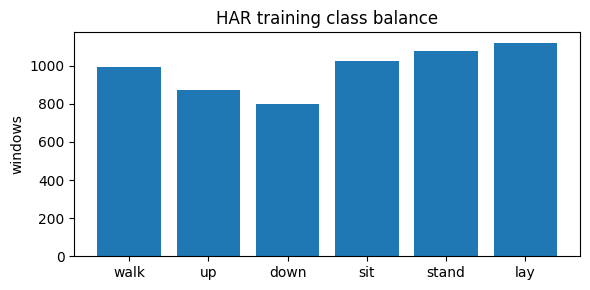

In [ ]:
"""
P1.06:  Subject-wise validation split
        Normalisation from training part only
        Class-balance plot
"""
def subject_split(seed):
    rng = np.random.default_rng(seed)
    tr_subj = np.unique(s_tr)                       # 21 subjects
    val_subj = rng.choice(tr_subj, 4, replace=False)
    vm = np.isin(s_tr, val_subj)
    return ~vm, vm                                  # (train_mask, val_mask)

def normalise(Xfit, *others):
    """mean/std per channel computed on Xfit only -> (9,) each"""
    mu = Xfit.mean(axis=(0,1), keepdims=True)       # (1,1,9)
    sd = Xfit.std(axis=(0,1),  keepdims=True) + 1e-8
    return [(o - mu)/sd for o in others], (mu, sd)

trm, vm = subject_split(SEEDS[0])
(Xtr_n, Xval_n), (mu, sd) = normalise(X_tr[trm], X_tr[trm], X_tr[vm])

# class balance
cnt = np.bincount(y_tr[trm], minlength=6)
names = ['walk','up','down','sit','stand','lay']
plt.figure(figsize=(6,3));
plt.bar(names, cnt);
plt.ylabel('windows')
plt.title('HAR training class balance');
plt.tight_layout();
plt.savefig('figures/p1_class_balance.png', dpi=150);
plt.show()

In [ ]:
"""
P1.07:  Adding Problem Generators
"""
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)

In [ ]:
"""
P1.08:  Assert cell
"""
for T in (50, 200):
    xb, yb = make_adding(64, T, 123)
    assert xb.shape == (64, T, 2)
    assert np.all(xb[:, :T//2, 1].sum(1) == 1)      # exactly one marker in first half
    assert np.all(xb[:, T//2:, 1].sum(1) == 1)      # exactly one in second half
    vals = (xb[:, :, 0] * xb[:, :, 1]).sum(1)       # marked value 1 + marked value 2
    assert np.allclose(vals, yb, atol=1e-6)
print(f'adding-problem tests passed; baseline MSE ={float(np.var(make_adding(2000, 100, 7)[1]))}')


adding-problem tests passed; baseline MSE =0.16064868867397308


In [ ]:
"""
P1.09:  Torch Datasets Loaders
"""
class ArrayDS(Dataset):
    def __init__(self, X, y): self.X, self.y = X, y
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return torch.from_numpy(self.X[i]), torch.tensor(self.y[i])

def har_loaders(seed, bs=128):
    trm, vm = subject_split(seed)
    # Unpack the (mu, sd) calculated for this specific seed's training split
    (Xtr_n, Xval_n), (mu_local, sd_local) = normalise(X_tr[trm], X_tr[trm], X_tr[vm])

    # Apply those local stats to the test set
    Xte_n = (X_te - mu_local) / sd_local

    return (DataLoader(ArrayDS(Xtr_n, y_tr[trm]),  batch_size=bs, shuffle=True),
            DataLoader(ArrayDS(Xval_n, y_tr[vm]),  batch_size=bs),
            DataLoader(ArrayDS(Xte_n, y_te), batch_size=bs))

In [ ]:
"""
P1.10:  Task1.2(p1.2):  RNN, LSTM and GRU cells from scratch
        Task Desc:      All three cells match their library layers (e.g. nn.LSTM) within 1e-5;
                        parameter counts explained, including the bias difference
        Class MyRNNCell created in this cell
"""
class MyRNNCell(nn.Module):
    """h_t = tanh(W_ih x_t + b_ih + W_hh h_{t-1} + b_hh)"""
    def __init__(self, d, h):
        super().__init__(); self.d, self.hidden_size = d, h
        self.weight_ih = nn.Parameter(torch.empty(h, d))   # (h, d)
        self.weight_hh = nn.Parameter(torch.empty(h, h))   # (h, h)
        self.bias_ih   = nn.Parameter(torch.empty(h))      # (h,)
        self.bias_hh   = nn.Parameter(torch.empty(h))      # (h,)
        k = 1/math.sqrt(h)
        for p in self.parameters(): nn.init.uniform_(p, -k, k)
    def forward(self, x, h):                               # x:(B,d) h:(B,h)
        return torch.tanh(x @ self.weight_ih.T + self.bias_ih
                          + h @ self.weight_hh.T + self.bias_hh)   # (B,h)

In [ ]:
"""
P1.11:  Assert cell for Class MyRNNCell
"""
c = MyRNNCell(9, 64)
assert c(torch.randn(4,9), torch.zeros(4,64)).shape == (4,64)

In [ ]:
"""
P1.12:  Class MyLSTMCell in this cell
"""
class MyLSTMCell(nn.Module):
    def __init__(self, d, h):
        super().__init__(); self.d, self.hidden_size = d, h
        self.weight_ih = nn.Parameter(torch.empty(4*h, d))   # (4h,d) rows = i,f,g,o
        self.weight_hh = nn.Parameter(torch.empty(4*h, h))   # (4h,h)
        self.bias_ih   = nn.Parameter(torch.empty(4*h))      # (4h,)
        self.bias_hh   = nn.Parameter(torch.empty(4*h))      # (4h,)
        k = 1/math.sqrt(h)
        for p in self.parameters(): nn.init.uniform_(p, -k, k)
    def forward(self, x, state):                             # x:(B,d)
        h, c = state                                          # h,c:(B,h)
        g = x @ self.weight_ih.T + self.bias_ih + h @ self.weight_hh.T + self.bias_hh  # (B,4h)
        i, f, gg, o = g.chunk(4, dim=1)                       # each (B,h)
        i, f, o = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o)
        gg = torch.tanh(gg)
        c_new = f*c + i*gg                                    # (B,h)
        h_new = o*torch.tanh(c_new)                           # (B,h)
        return h_new, c_new

In [ ]:
"""
P1.13:  Assert Cell for Class MyLSTMCell
"""
h,c = MyLSTMCell(9,64)(torch.randn(4,9), (torch.zeros(4,64), torch.zeros(4,64)))
assert h.shape == c.shape == (4,64)

In [ ]:
"""
P1.14:  Class MyGRUCell in this cell
"""
class MyGRUCell(nn.Module):
    def __init__(self, d, h):
        super().__init__(); self.d, self.hidden_size = d, h
        self.weight_ih = nn.Parameter(torch.empty(3*h, d))   # (3h,d) rows = r,z,n
        self.weight_hh = nn.Parameter(torch.empty(3*h, h))   # (3h,h)
        self.bias_ih   = nn.Parameter(torch.empty(3*h))
        self.bias_hh   = nn.Parameter(torch.empty(3*h))
        k = 1/math.sqrt(h)
        for p in self.parameters(): nn.init.uniform_(p, -k, k)
    def forward(self, x, h):                                  # x:(B,d) h:(B,h)
        gi = x @ self.weight_ih.T + self.bias_ih              # (B,3h)
        gh = h @ self.weight_hh.T + self.bias_hh              # (B,3h)
        r_i, z_i, n_i = gi.chunk(3, dim=1)                    # each (B,h)
        r_h, z_h, n_h = gh.chunk(3, dim=1)
        r = torch.sigmoid(r_i + r_h)
        z = torch.sigmoid(z_i + z_h)
        n = torch.tanh(n_i + r*n_h)
        return (1-z)*n + z*h                                  # (B,h)

In [ ]:
"""
P1.15:  Assert Cell for Class MyGRUCell
"""
assert MyGRUCell(9,64)(torch.randn(4,9), torch.zeros(4,64)).shape == (4,64)

In [ ]:
"""
P1.16:  Unroll helper, weight copy and match library
"""
def unroll(cell, x):                     # x:(B,T,d) -> outs:(B,T,h), last state
    B,T,_ = x.shape
    if isinstance(cell, MyLSTMCell):
        h = torch.zeros(B, cell.hidden_size); c = torch.zeros(B, cell.hidden_size)
        outs = []
        for t in range(T):
            h, c = cell(x[:,t], (h, c)); outs.append(h)
        return torch.stack(outs,1), (h, c)
    h = torch.zeros(B, cell.hidden_size); outs = []
    for t in range(T):
        h = cell(x[:,t], h); outs.append(h)
    return torch.stack(outs,1), h

def copy_from(ref, cell):
    """copy nn.RNN/nn.LSTM/nn.GRU layer-0 params into a My*Cell"""
    with torch.no_grad():
        cell.weight_ih.copy_(ref.weight_ih_l0);
        cell.weight_hh.copy_(ref.weight_hh_l0)
        cell.bias_ih.copy_(ref.bias_ih_l0);
        cell.bias_hh.copy_(ref.bias_hh_l0)

In [ ]:
"""
P1.17:   Assert cell [Error should be less than 1e-5]
"""
torch.manual_seed(0); d, h, B, T = 9, 64, 4, 20
x = torch.randn(B, T, d)

for name, RefLayer, Cell in [('rnn', nn.RNN, MyRNNCell),
                             ('lstm', nn.LSTM, MyLSTMCell),
                             ('gru', nn.GRU, MyGRUCell)]:
    ref = RefLayer(d, h, batch_first=True)
    mine = Cell(d, h); copy_from(ref, mine)
    out_ref, _ = ref(x)
    out_mine, _ = unroll(mine, x)
    err = (out_ref - out_mine).abs().max().item()
    print(f'{name}: max|diff| = {err:.2e}')
    assert err < 1e-5

rnn: max|diff| = 1.19e-07
lstm: max|diff| = 5.96e-08
gru: max|diff| = 6.71e-08


In [ ]:
"""
P1.18:   Parameter counts, by hand vs code vs PyTorch (d=9, h=64)
"""
d, h = 9, 64
hand = {'rnn':  h*d + h*h + h,            # one bias  = 4736
        'lstm': 4*(h*d + h*h + h),        #           = 18944
        'gru':  3*(h*d + h*h + h)}        #           = 14208
for name, RefLayer, Cell in [('rnn', nn.RNN, MyRNNCell),
                             ('lstm', nn.LSTM, MyLSTMCell),
                             ('gru', nn.GRU, MyGRUCell)]:
    mine, ref = Cell(d,h), RefLayer(d,h, batch_first=True)
    print(name, 'hand:', hand[name], '| my code:', n_params(mine),
          '| nn layer:', n_params(ref), '| diff = 2 biases?', n_params(ref)-n_params(mine) == h)

rnn hand: 4736 | my code: 4800 | nn layer: 4800 | diff = 2 biases? False
lstm hand: 18944 | my code: 19200 | nn layer: 19200 | diff = 2 biases? False
gru hand: 14208 | my code: 14400 | nn layer: 14400 | diff = 2 biases? False


In [ ]:
"""
P1.19:  Task1.3(p1.3):  HAR Classifications
        Task Desc:      Same budget for all three, 3 seeds, mean ± std, parameters,
                        time and confusion matrix reported
        Model and Training loop
        Class RecurrentClassifier
"""
class RecurrentClassifier(nn.Module):
    def __init__(self, kind, d_in=9, hidden=HIDDEN, n_classes=6):
        super().__init__()
        RNN = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}[kind]
        self.rnn = RNN(d_in, hidden, batch_first=True)
        self.fc  = nn.Linear(hidden, n_classes)
    def forward(self, x):                       # x:(B,128,9)
        out, h = self.rnn(x)                    # out:(B,128,H)
        if isinstance(h, tuple): h = h[0]       # LSTM -> (h,c)
        return self.fc(h[-1])                   # (B,6) from last hidden state

@torch.no_grad()
def evaluate_clf(model, dl):
    model.eval(); P, Y = [], []
    for xb, yb in dl:
        P.append(model(xb.to(device)).argmax(1).cpu()); Y.append(yb)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def train_clf(model, tr, va, epochs=20, lr=1e-3, clip=None):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    t0 = time.time()
    for ep in range(epochs):
        model.train(); tot = n = 0
        for xb, yb in tr:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            if clip: nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step(); tot += loss.item()*len(xb); n += len(xb)
        yp, yt = evaluate_clf(model, va)
        hist['train_loss'].append(tot/n)
        hist['val_loss'].append(float('nan'))
        hist['val_acc'].append((yp == yt).mean())
    hist['sec_per_epoch'] = (time.time()-t0)/epochs
    return hist

In [ ]:
"""
P1.20:   3 Models × 3 Seeds of identical budget
"""
EPOCHS, BS, LR = 20, 128, 1e-3
p1_results = {}
for seed in SEEDS:
    tr, va, te = har_loaders(seed, BS)
    for kind in ['rnn', 'lstm', 'gru']:
        set_seed(seed)
        m = RecurrentClassifier(kind).to(device)
        hist = train_clf(m, tr, va, EPOCHS, LR)
        yp, yt = evaluate_clf(m, te)
        acc = (yp == yt).mean(); f1 = f1_score(yt, yp, average='macro')
        p1_results[(kind, seed)] = (m, acc, f1, yp, yt, hist)
        log_run(problem='1.3', model=kind, seed=seed, seq_len=128,
                test_acc=round(float(acc),4), macro_f1=round(float(f1),4),
                params=n_params(m), sec_per_epoch=round(hist['sec_per_epoch'],2))
        print(kind, seed, f'acc={acc:.4f} f1={f1:.4f}')

rnn 0 acc=0.7228 f1=0.7114
lstm 0 acc=0.8904 f1=0.8921
gru 0 acc=0.8884 f1=0.8872
rnn 1 acc=0.7038 f1=0.6974
lstm 1 acc=0.8863 f1=0.8862
gru 1 acc=0.8921 f1=0.8918
rnn 2 acc=0.6797 f1=0.6600
lstm 2 acc=0.8985 f1=0.8989
gru 2 acc=0.8751 f1=0.8757


  model         test acc         macro-F1  params s/epoch
0   rnn  0.7021 ± 0.0216  0.6896 ± 0.0266    5190     0.2
1  lstm  0.8918 ± 0.0062  0.8924 ± 0.0063   19590     0.2
2   gru  0.8852 ± 0.0089  0.8849 ± 0.0083   14790     0.2


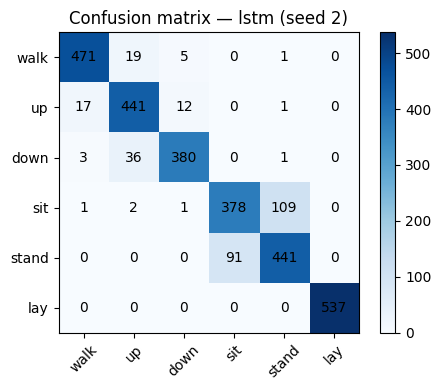

In [ ]:
"""
P1.21:   Mean +/- Std table + Confusion matrix of best model
"""
import pandas as pd
rows = []
for kind in ['rnn','lstm','gru']:
    a = np.array([p1_results[(kind,s)][1] for s in SEEDS])
    f = np.array([p1_results[(kind,s)][2] for s in SEEDS])
    t = np.mean([p1_results[(kind,s)][5]['sec_per_epoch'] for s in SEEDS])
    rows.append([kind, f'{a.mean():.4f} ± {a.std(ddof=1):.4f}',
                 f'{f.mean():.4f} ± {f.std(ddof=1):.4f}',
                 n_params(p1_results[(kind,SEEDS[0])][0]), f'{t:.1f}'])
print(pd.DataFrame(rows, columns=['model','test acc','macro-F1','params','s/epoch']))

best = max(p1_results, key=lambda k: p1_results[k][1])
cm = confusion_matrix(p1_results[best][4], p1_results[best][3])
plt.figure(figsize=(5,4)); plt.imshow(cm, cmap='Blues')
plt.xticks(range(6), names, rotation=45); plt.yticks(range(6), names)
for i in range(6):
    for j in range(6): plt.text(j, i, cm[i,j], ha='center', va='center')
plt.title(f'Confusion matrix — {best[0]} (seed {best[1]})');
plt.colorbar()
plt.tight_layout();
plt.savefig('figures/p1_confusion_best.png', dpi=150);
plt.show()

In [ ]:
"""
P1.22:  Task1.4(p1.4):  Adding problem
        Task Desc:      T = 50, 100, 200, 400 × 3 models × 3 seeds;
                        MSE against the 0.167 baseline; solved-run table;
                        Curves at T = 200
        Regressor + Training
        Class AddingRegressor in this cell
"""
class AddingRegressor(nn.Module):
    def __init__(self, kind, hidden=HIDDEN):
        super().__init__()
        RNN = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}[kind]
        self.rnn = RNN(2, hidden, batch_first=True)
        self.fc  = nn.Linear(hidden, 1)
    def forward(self, x):                      # x:(B,T,2)
        out, h = self.rnn(x)
        if isinstance(h, tuple): h = h[0]
        return self.fc(h[-1]).squeeze(-1)      # (B,)

def train_add(model, T, seed, epochs=15, bs=128, lr=1e-3, clip=None):
    Xtr, ytr = make_adding(10_000, T, 0)
    Xva, yva = make_adding(1_000,  T, 1)
    Xte, yte = make_adding(1_000,  T, 2)
    mk = lambda X,y,sh: DataLoader(ArrayDS(X,y), batch_size=bs, shuffle=sh)
    tr, va, te = mk(Xtr,ytr,True), mk(Xva,yva,False), mk(Xte,yte,False)
    opt = torch.optim.Adam(model.parameters(), lr=lr); hist = []
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        for xb, yb in tr:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = F.mse_loss(model(xb), yb); loss.backward()
            if clip: nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
        model.eval()
        with torch.no_grad():
            v = np.mean([F.mse_loss(model(xb.to(device)), yb.to(device)).item() for xb,yb in va])
        hist.append(v)
    model.eval()
    with torch.no_grad():
        te_mse = np.mean([F.mse_loss(model(xb.to(device)), yb.to(device)).item() for xb,yb in te])
    return te_mse, hist, (time.time()-t0)/epochs

In [ ]:
"""
P1.23:   Sweep T × Model × Seed
"""
p14 = {}
for T in [50, 100, 200, 400]:
    for kind in ['rnn','lstm','gru']:
        for seed in SEEDS:
            set_seed(seed)
            m = AddingRegressor(kind).to(device)
            mse, hist, spe = train_add(m, T, seed, clip=1.0)
            p14[(T,kind,seed)] = (m, mse, hist)
            log_run(problem='1.4', model=kind, seed=seed, seq_len=T,
                    test_mse=round(float(mse),4), params=n_params(m),
                    sec_per_epoch=round(spe,2), notes=f'solved={mse<0.05}')
            print(T, kind, seed, f'{mse:.4f}')

50 rnn 0 0.1758
50 rnn 1 0.1746
50 rnn 2 0.1720
50 lstm 0 0.1263
50 lstm 1 0.1727
50 lstm 2 0.1257
50 gru 0 0.0050
50 gru 1 0.0063
50 gru 2 0.0078
100 rnn 0 0.1699
100 rnn 1 0.1695
100 rnn 2 0.1696
100 lstm 0 0.1695
100 lstm 1 0.1704
100 lstm 2 0.1692
100 gru 0 0.0108
100 gru 1 0.0091
100 gru 2 0.0108
200 rnn 0 0.1687
200 rnn 1 0.1680
200 rnn 2 0.1759
200 lstm 0 0.1724
200 lstm 1 0.1684
200 lstm 2 0.1680
200 gru 0 0.1601
200 gru 1 0.0297
200 gru 2 0.1473
400 rnn 0 0.1545
400 rnn 1 0.1533
400 rnn 2 0.1527
400 lstm 0 0.1530
400 lstm 1 0.1543
400 lstm 2 0.1529
400 gru 0 0.1524
400 gru 1 0.1533
400 gru 2 0.1510


  model           T=50          T=100          T=200          T=400  solved/12
0   rnn  0.174 ± 0.002  0.170 ± 0.000  0.171 ± 0.004  0.154 ± 0.001          0
1  lstm  0.142 ± 0.027  0.170 ± 0.001  0.170 ± 0.002  0.153 ± 0.001          0
2   gru  0.006 ± 0.001  0.010 ± 0.001  0.112 ± 0.072  0.152 ± 0.001          7
baseline (always 1.0) MSE ≈ 0.167


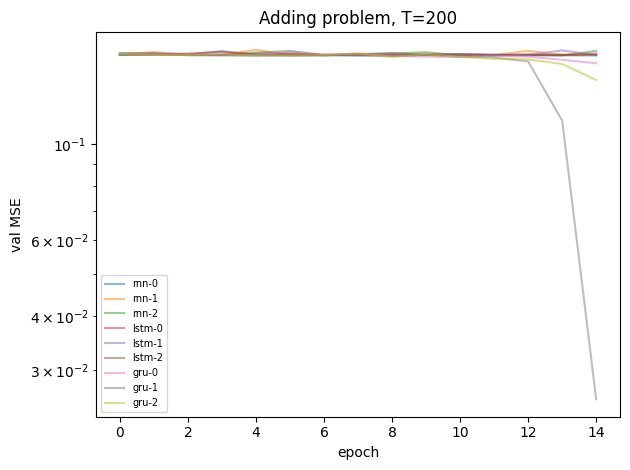

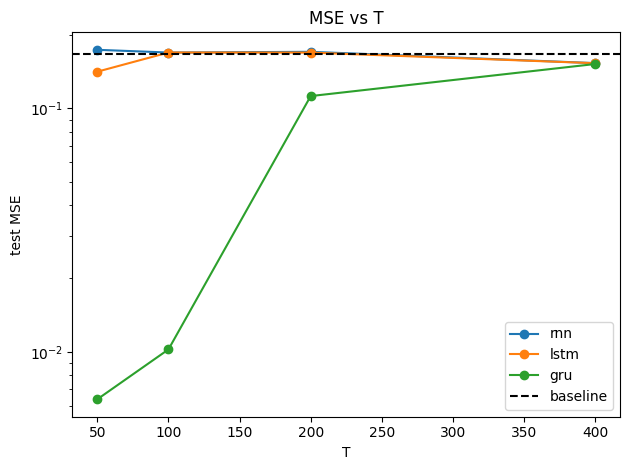

In [ ]:
"""
P1.24:   MSE vs T table + solved-run count + learning curves at T=200
"""
tab = []
for kind in ['rnn','lstm','gru']:
    r = [kind]
    for T in [50,100,200,400]:
        v = np.array([p14[(T,kind,s)][1] for s in SEEDS])
        r.append(f'{v.mean():.3f} ± {v.std(ddof=1):.3f}')
    r.append(sum(p14[(T,kind,s)][1] < 0.05 for T in [50,100,200,400] for s in SEEDS))
    tab.append(r)
print(pd.DataFrame(tab, columns=['model','T=50','T=100','T=200','T=400','solved/12']))
print('baseline (always 1.0) MSE ≈ 0.167')

plt.figure()
for kind in ['rnn','lstm','gru']:
    for s in SEEDS:
        plt.plot(p14[(200,kind,s)][2], alpha=.5, label=f'{kind}-{s}')
plt.yscale('log');
plt.xlabel('epoch');
plt.ylabel('val MSE');
plt.legend(fontsize=7)
plt.title('Adding problem, T=200');
plt.tight_layout()
plt.savefig('figures/p1_adding_curves_T200.png', dpi=150);
plt.show()

plt.figure()
for kind in ['rnn','lstm','gru']:
    mu = [np.mean([p14[(T,kind,s)][1] for s in SEEDS]) for T in [50,100,200,400]]
    plt.plot([50,100,200,400], mu, marker='o', label=kind)
plt.axhline(0.167, ls='--', c='k', label='baseline');
plt.yscale('log')
plt.xlabel('T');
plt.ylabel('test MSE');
plt.legend();
plt.title('MSE vs T')
plt.tight_layout();
plt.savefig('figures/p1_mse_vs_T.png', dpi=150);
plt.show()

shape: (100,) | min/max: 1.0910029622918185e-22 0.016828011721372604 | any NaN: False


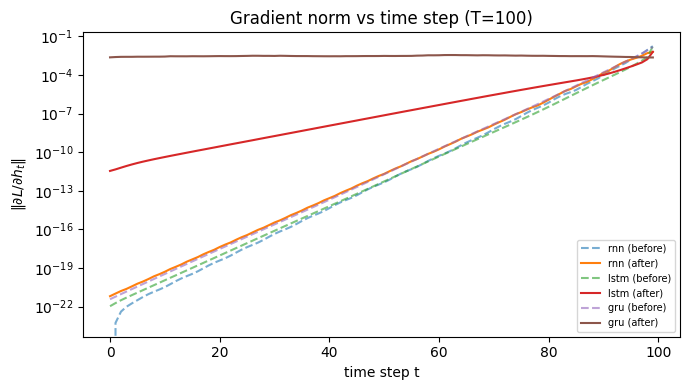

In [ ]:
"""
P1.25:  Task1.5(p1.5):  Gradients, ablations and analysis
        Task Desc:      Gradient-norm plot, hidden-size sweep, individual ablation;
                        conclusions backed by the tables;
                        wearable recommendation justified
        '||dL/dh_t|| vs t' Before and After training, T=100
"""
def grad_norms_by_step(model, kind, T=100, seed=0, bs=64):
    X, y = make_adding(bs, T, seed)
    xb = torch.tensor(X).to(device)
    yb = torch.tensor(y).to(device)

    # 1. Instantiate the cell and copy weights from the trained model
    if kind == 'rnn':
        cell = nn.RNNCell(2, HIDDEN).to(device)
    elif kind == 'lstm':
        cell = nn.LSTMCell(2, HIDDEN).to(device)
    else:
        cell = nn.GRUCell(2, HIDDEN).to(device)

    with torch.no_grad():
        cell.weight_ih.copy_(model.rnn.weight_ih_l0)
        cell.weight_hh.copy_(model.rnn.weight_hh_l0)
        cell.bias_ih.copy_(model.rnn.bias_ih_l0)
        cell.bias_hh.copy_(model.rnn.bias_hh_l0)

    # 2. Manual unroll so each h_t is a separate node
    h = torch.zeros(bs, HIDDEN, device=device)
    if kind == 'lstm':
        c = torch.zeros(bs, HIDDEN, device=device)

    hs = []
    for t in range(T):
        if kind == 'lstm':
            h, c = cell(xb[:, t], (h, c))
        else:
            h = cell(xb[:, t], h)

        h.retain_grad()
        hs.append(h)

    out_last = hs[-1]  # shape (B, H)
    pred = model.fc(out_last).squeeze(-1)
    loss = F.mse_loss(pred, yb)

    # 3. Backward
    loss.backward()

    # 4. Extract gradient norms
    norms = []
    for h_t in hs:
        # h_t.grad is dL/dh_t, shape (B, H)
        norms.append(h_t.grad.norm(dim=-1).mean().item())

    return np.array(norms)

#Sanity check before running the full plot
set_seed(0); fresh = AddingRegressor('lstm').to(device)
g = grad_norms_by_step(fresh, 'lstm')
print('shape:', g.shape, '| min/max:', g.min(), g.max(), '| any NaN:', np.isnan(g).any())
# expect: shape (100,), no NaN, values that decay or grow across t

plt.figure(figsize=(7,4))
for kind in ['rnn','lstm','gru']:
    m = p14[(100, kind, SEEDS[0])][0]                       # trained model
    set_seed(0); fresh = AddingRegressor(kind).to(device)   # untrained

    # Note the extra 'kind' argument here
    plt.plot(grad_norms_by_step(fresh, kind), '--', alpha=.6, label=f'{kind} (before)')
    plt.plot(grad_norms_by_step(m, kind),      '-',  label=f'{kind} (after)')

plt.yscale('log')
plt.xlabel('time step t'); plt.ylabel(r'$\|\partial L/\partial h_t\|$')
plt.legend(fontsize=7); plt.title('Gradient norm vs time step (T=100)')
plt.tight_layout(); savefig('p1_gradnorm.png'); plt.show()

   hidden model       acc  params   s/epoch
0      16  lstm  0.840855    1830  0.192964
1      16   gru  0.886664    1398  0.221848
2      32  lstm  0.887343    5702  0.193240
3      32   gru  0.896844    4326  0.187274
4      64  lstm  0.890397   19590  0.231913
5      64   gru  0.888361   14790  0.189955
6     128  lstm  0.880217   71942  0.395741
7     128   gru  0.884628   54150  0.269122


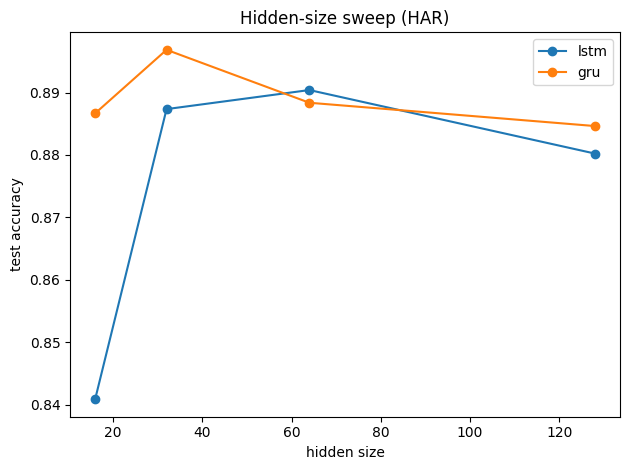

In [ ]:
"""
P1.26:   Hidden-size sweep for LSTM & GRU on HAR
"""
sweep = []
for hsize in [16, 32, 64, 128]:
    for kind in ['lstm','gru']:
        set_seed(SEEDS[0])
        m = RecurrentClassifier(kind, hidden=hsize).to(device)
        tr, va, te = har_loaders(SEEDS[0])
        hist = train_clf(m, tr, va, EPOCHS, LR)
        yp, yt = evaluate_clf(m, te); acc = (yp==yt).mean()
        sweep.append([hsize, kind, acc, n_params(m), hist['sec_per_epoch']])
        log_run(problem='1.5b', model=kind, seed=SEEDS[0], seq_len=128,
                test_acc=round(float(acc),4), params=n_params(m),
                sec_per_epoch=round(hist['sec_per_epoch'],2), notes=f'hidden={hsize}')
df = pd.DataFrame(sweep, columns=['hidden','model','acc','params','s/epoch'])
print(df)
plt.figure()
for kind in ['lstm','gru']:
    d_ = df[df.model==kind];
    plt.plot(d_.hidden, d_.acc, marker='o', label=kind)
plt.xlabel('hidden size');
plt.ylabel('test accuracy');
plt.legend()
plt.title('Hidden-size sweep (HAR)');
plt.tight_layout()
plt.savefig('figures/p1_hidden_sweep.png', dpi=150);
plt.show()

clip None | seed 0 | MSE=0.1688
clip None | seed 1 | MSE=0.1684
clip None | seed 2 | MSE=0.1703
clip 1.0 | seed 0 | MSE=0.1796
clip 1.0 | seed 1 | MSE=0.1722
clip 1.0 | seed 2 | MSE=0.1703


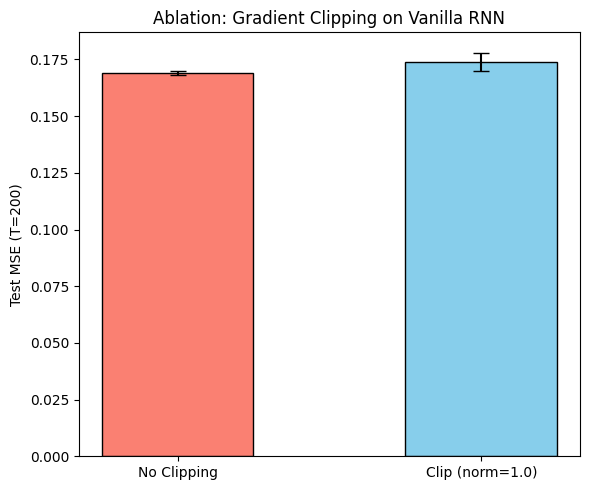

In [ ]:
"""
P1.27:  Induvidual Ablation: Clipping vs None, Vanilla RNN, T=200
"""
import numpy as np
import matplotlib.pyplot as plt

# Dictionary to store results for plotting
ablation_results = {None: [], 1.0: []}

for clip in [None, 1.0]:
    for seed in SEEDS:
        set_seed(seed)
        m = AddingRegressor('rnn').to(device)
        # Using lr=1e-2 to induce exploding gradients for the ablation
        mse, hist, spe = train_add(m, 200, seed, epochs=15, lr=1e-2, clip=clip)

        ablation_results[clip].append(mse)

        log_run(problem='1.5c', model='rnn', seed=seed, seq_len=200,
                test_mse=round(float(mse), 4) if not np.isnan(mse) else 'NaN',
                params=n_params(m), sec_per_epoch=round(spe, 2),
                notes=f'clip={clip}')
        print(f'clip {clip} | seed {seed} | MSE={mse:.4f}')

# --- Plotting the Bar Chart ---
means = [np.nanmean(ablation_results[None]), np.nanmean(ablation_results[1.0])]
stds  = [np.nanstd(ablation_results[None]),  np.nanstd(ablation_results[1.0])]

plt.figure(figsize=(6, 5))
# Use placeholder y-values if NaN to avoid crashing the plot
plot_means = [0.001 if np.isnan(m) else m for m in means]

bars = plt.bar(['No Clipping', 'Clip (norm=1.0)'], plot_means, yerr=stds,
               capsize=6, color=['salmon', 'skyblue'], edgecolor='black', width=0.5)

# Handle divergence (NaN) or large values gracefully
if np.isnan(means[0]) or means[0] > 10:
    plt.yscale('log')
    if np.isnan(means[0]):
        plt.text(0, 0.001, 'Diverged\n(NaN)', ha='center', va='center',
                 color='red', fontweight='bold', fontsize=11)

plt.ylabel('Test MSE (T=200)')
plt.title('Ablation: Gradient Clipping on Vanilla RNN')
plt.tight_layout()
savefig('p1_ablation_clip.png')
plt.show()

# bar plot of the two conditions (mean ± std over seeds)

In [ ]:
"""
P1.28:  Cleaning up the results.csv. De-duplicating the report for multiple runs
        Saving it in the main directory as 2026aj05620_DNN_Assignment/result.csv
"""

import pandas as pd

# Load the messy csv
df = pd.read_csv('results.csv')

# Drop duplicates based on problem, model, seed, seq_len, and notes
# keep='last' means if you ran it twice, it keeps the most recent result
df_clean = df.drop_duplicates(subset=['problem', 'model', 'seed', 'seq_len', 'notes'], keep='last')

# Save it back
df_clean.to_csv('../results.csv', index=False)
print(f"Cleaned! Removed {len(df) - len(df_clean)} duplicate rows.")
print("Remaining rows per problem:\n", df_clean['problem'].value_counts())

Cleaned! Removed 51 duplicate rows.
Remaining rows per problem:
 problem
1.4     36
1.3      9
1.5b     8
1.5c     6
Name: count, dtype: int64


Markdown on Analysis